<a href="https://colab.research.google.com/github/StasyEby/portfolio/blob/main/explainable_loan_decision_engine.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
project_name = "Explainable Loan Decision Engine"

print("My first Explainable AI project")
print(project_name)


My first Explainable AI project
Explainable Loan Decision Engine


In [2]:
import pandas as pd

# Create a sample loan dataset
loan_data = {
    "applicant_id": [1001, 1002, 1003, 1004, 1005, 1006, 1007, 1008],
    "monthly_income": [250000, 120000, 450000, 180000,
                       350000, 90000, 500000, 220000],
    "employment_years": [5, 1, 10, 3, 8, 0, 12, 4],
    "loan_amount": [500000, 300000, 700000, 400000,
                    600000, 250000, 800000, 350000],
    "existing_debt": [80000, 70000, 50000, 120000,
                      60000, 80000, 100000, 50000],
    "credit_history": ["Good", "Poor", "Good", "Fair",
                       "Good", "Poor", "Good", "Fair"],
    "previous_default": ["No", "Yes", "No", "No",
                         "No", "Yes", "No", "No"],
    "loan_approved": ["Yes", "No", "Yes", "No",
                      "Yes", "No", "Yes", "Yes"]
}

# Convert the data into a Pandas DataFrame
df = pd.DataFrame(loan_data)

# Display the dataset
print(df)

   applicant_id  monthly_income  employment_years  loan_amount  existing_debt  \
0          1001          250000                 5       500000          80000   
1          1002          120000                 1       300000          70000   
2          1003          450000                10       700000          50000   
3          1004          180000                 3       400000         120000   
4          1005          350000                 8       600000          60000   
5          1006           90000                 0       250000          80000   
6          1007          500000                12       800000         100000   
7          1008          220000                 4       350000          50000   

  credit_history previous_default loan_approved  
0           Good               No           Yes  
1           Poor              Yes            No  
2           Good               No           Yes  
3           Fair               No            No  
4           Good    

In [3]:
# Display the first five records
print("FIRST FIVE RECORDS")
print(df.head())

# Check dataset dimensions
print("\nDATASET SHAPE")
print(df.shape)

# Check column names and data types
print("\nDATASET INFORMATION")
print(df.info())

# Check for missing values
print("\nMISSING VALUES")
print(df.isnull().sum())

# Examine statistical information
print("\nSTATISTICAL SUMMARY")
print(df.describe())

FIRST FIVE RECORDS
   applicant_id  monthly_income  employment_years  loan_amount  existing_debt  \
0          1001          250000                 5       500000          80000   
1          1002          120000                 1       300000          70000   
2          1003          450000                10       700000          50000   
3          1004          180000                 3       400000         120000   
4          1005          350000                 8       600000          60000   

  credit_history previous_default loan_approved  
0           Good               No           Yes  
1           Poor              Yes            No  
2           Good               No           Yes  
3           Fair               No            No  
4           Good               No           Yes  

DATASET SHAPE
(8, 8)

DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8 entries, 0 to 7
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype 
---  

In [4]:
# Count approved and declined loans
print(df["loan_approved"].value_counts())

# Calculate average monthly income
print(df["monthly_income"].mean())

# Calculate average loan amount
print(df["loan_amount"].mean())

# Compare average income by loan outcome
print(df.groupby("loan_approved")["monthly_income"].mean())

loan_approved
Yes    5
No     3
Name: count, dtype: int64
270000.0
487500.0
loan_approved
No     130000.0
Yes    354000.0
Name: monthly_income, dtype: float64


In [5]:

import pandas as pd
import numpy as np

# Make results reproducible
np.random.seed(42)

# Generate 1,000 synthetic applicants
n = 1000

df = pd.DataFrame({
    "monthly_income": np.random.randint(80000, 800001, n),
    "employment_years": np.random.randint(0, 21, n),
    "loan_amount": np.random.randint(100000, 2000001, n),
    "existing_debt": np.random.randint(0, 300001, n),
    "credit_history": np.random.choice(
        ["Good", "Fair", "Poor"], n,
        p=[0.5, 0.3, 0.2]
    ),
    "previous_default": np.random.choice(
        ["Yes", "No"], n,
        p=[0.2, 0.8]
    )
})

# Create an illustrative synthetic outcome
score = (
    (df["monthly_income"] / 100000) * 0.8
    + df["employment_years"] * 0.15
    - (df["loan_amount"] / 100000) * 0.4
    - (df["existing_debt"] / 100000) * 0.5
    + df["credit_history"].map({
        "Good": 1.5, "Fair": 0.5, "Poor": -1
    })
    + df["previous_default"].map({
        "Yes": -2, "No": 0.5
    })
    + np.random.normal(0, 1.5, n)
)

df["loan_approved"] = np.where(
    score > 1.5, "Yes", "No"
)

print(df.head())
print("\nDataset shape:", df.shape)
print("\nLoan outcomes:")
print(df["loan_approved"].value_counts())


   monthly_income  employment_years  loan_amount  existing_debt  \
0          201958                 4      1393590          81912   
1          751155                11       256498         137660   
2          211932                17      1166348         268448   
3          445838                13       890144           7345   
4          339178                20       494583         160372   

  credit_history previous_default loan_approved  
0           Good               No            No  
1           Poor               No           Yes  
2           Fair               No            No  
3           Good               No           Yes  
4           Good               No           Yes  

Dataset shape: (1000, 7)

Loan outcomes:
loan_approved
No     591
Yes    409
Name: count, dtype: int64


In [6]:

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Select input features
X = df.drop(columns=["loan_approved"])

# Select prediction target
y = df["loan_approved"].map({
    "No": 0,
    "Yes": 1
})

# Identify numerical and categorical features
numeric_features = [
    "monthly_income",
    "employment_years",
    "loan_amount",
    "existing_debt"
]

categorical_features = [
    "credit_history",
    "previous_default"
]

# Prepare numerical and categorical data
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"),
         categorical_features)
    ]
)

# Create the machine learning pipeline
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Train the model
model.fit(X_train, y_train)

# Generate predictions
predictions = model.predict(X_test)

# Evaluate the model
print("MODEL ACCURACY:")
print(accuracy_score(y_test, predictions))

print("\nCLASSIFICATION REPORT:")
print(classification_report(y_test, predictions))

print("\nCONFUSION MATRIX:")
print(confusion_matrix(y_test, predictions))


MODEL ACCURACY:
0.87

CLASSIFICATION REPORT:
              precision    recall  f1-score   support

           0       0.86      0.93      0.89       118
           1       0.89      0.78      0.83        82

    accuracy                           0.87       200
   macro avg       0.87      0.86      0.86       200
weighted avg       0.87      0.87      0.87       200


CONFUSION MATRIX:
[[110   8]
 [ 18  64]]


In [7]:

# Create a new loan application
new_applicant = pd.DataFrame({
    "monthly_income": [350000],
    "employment_years": [6],
    "loan_amount": [500000],
    "existing_debt": [60000],
    "credit_history": ["Good"],
    "previous_default": ["No"]
})

print(new_applicant)


   monthly_income  employment_years  loan_amount  existing_debt  \
0          350000                 6       500000          60000   

  credit_history previous_default  
0           Good               No  


In [8]:

# Predict the loan outcome
prediction = model.predict(new_applicant)

if prediction[0] == 1:
    print("Predicted outcome: APPROVED")
else:
    print("Predicted outcome: DECLINED")


Predicted outcome: APPROVED


In [9]:

# Obtain probabilities for both outcomes
probabilities = model.predict_proba(new_applicant)[0]

# Identify the class corresponding to approval
classifier = model.named_steps["classifier"]
approval_index = list(classifier.classes_).index(1)

approval_probability = probabilities[approval_index]

print(
    "Model-estimated approval probability:",
    round(approval_probability * 100, 2),
    "%"
)


Model-estimated approval probability: 89.01 %


In [10]:

from sklearn.metrics import (
    confusion_matrix,
    classification_report
)

# Display confusion matrix
cm = confusion_matrix(y_test, predictions)

print("CONFUSION MATRIX")
print(cm)

# Display detailed performance metrics
print("\nDETAILED MODEL PERFORMANCE")
print(classification_report(
    y_test,
    predictions,
    target_names=["Declined", "Approved"]
))


CONFUSION MATRIX
[[110   8]
 [ 18  64]]

DETAILED MODEL PERFORMANCE
              precision    recall  f1-score   support

    Declined       0.86      0.93      0.89       118
    Approved       0.89      0.78      0.83        82

    accuracy                           0.87       200
   macro avg       0.87      0.86      0.86       200
weighted avg       0.87      0.87      0.87       200



In [11]:
!pip install shap

In [12]:
import shap

print("SHAP version:", shap.__version__)
print("SHAP successfully imported!")

SHAP version: 0.54.1
SHAP successfully imported!


In [13]:
# Access the trained preprocessing component
preprocessor = model.named_steps["preprocessor"]

# Access the trained Logistic Regression model
classifier = model.named_steps["classifier"]

# Transform training data
X_train_transformed = preprocessor.transform(X_train)

# Transform testing data
X_test_transformed = preprocessor.transform(X_test)

# Get the processed feature names
feature_names = preprocessor.get_feature_names_out()

print("Processed feature names:")
print(feature_names)

print("\nNumber of processed features:")
print(len(feature_names))

Processed feature names:
['num__monthly_income' 'num__employment_years' 'num__loan_amount'
 'num__existing_debt' 'cat__credit_history_Fair'
 'cat__credit_history_Good' 'cat__credit_history_Poor'
 'cat__previous_default_No' 'cat__previous_default_Yes']

Number of processed features:
9


In [14]:
# Create SHAP explainer
explainer = shap.Explainer(
    classifier,
    X_train_transformed,
    feature_names=feature_names
)

print("SHAP explainer successfully created!")

SHAP explainer successfully created!


In [15]:
# Transform the new loan application
new_applicant_transformed = preprocessor.transform(
    new_applicant
)

# Generate SHAP explanation
shap_values = explainer(
    new_applicant_transformed
)

print("SHAP explanation generated successfully!")

SHAP explanation generated successfully!


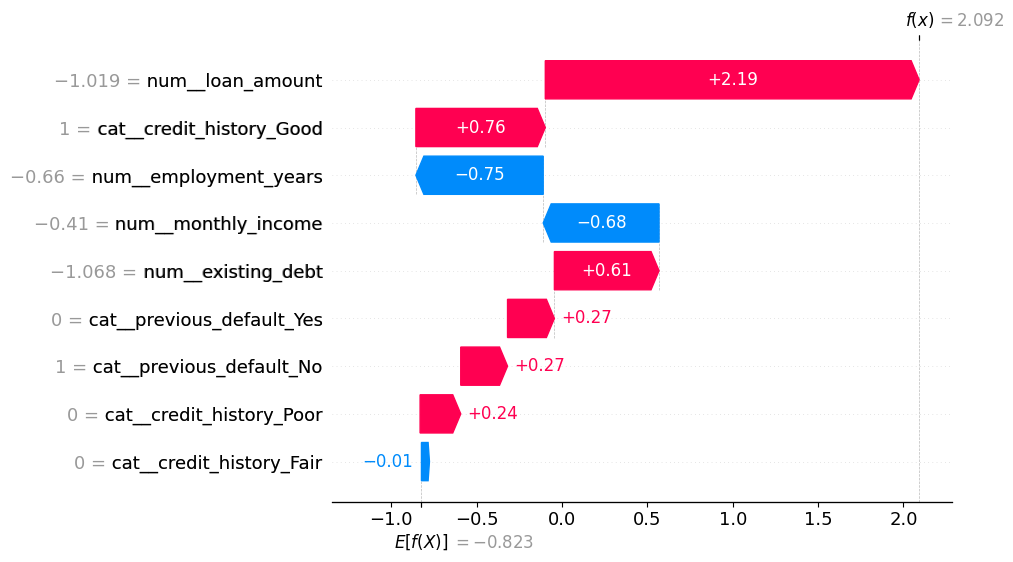

In [16]:
shap.plots.waterfall(shap_values[0])

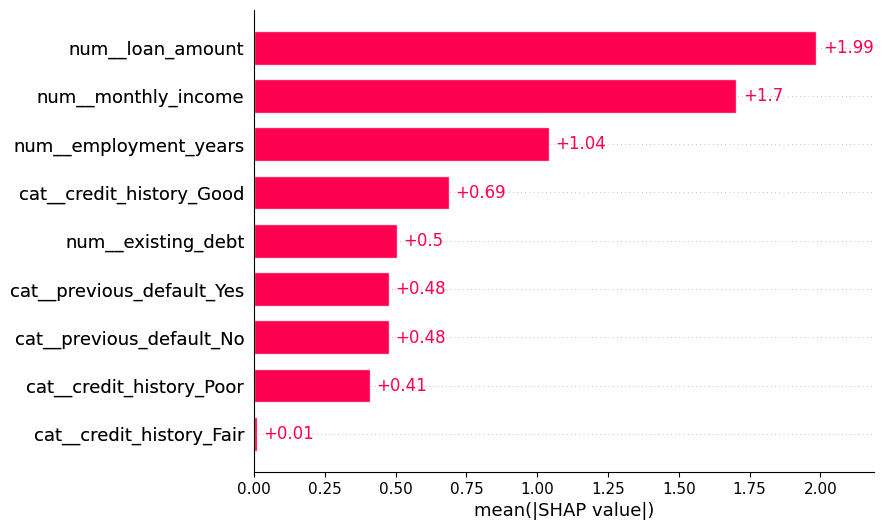

In [17]:
# Generate SHAP explanations for test applications
all_shap_values = explainer(X_test_transformed)

# Display global feature importance
shap.plots.bar(all_shap_values)

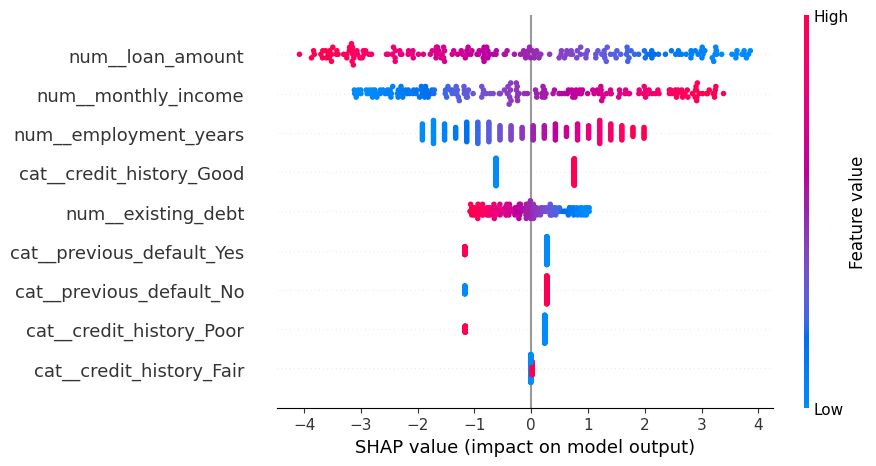

In [18]:
shap.plots.beeswarm(all_shap_values)

In [19]:
!pip install streamlit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.2/11.2 MB 23.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 43.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [streamlit]


In [20]:
import streamlit as st

print("Streamlit installed successfully!")

Streamlit installed successfully!


In [21]:
import joblib

# Save your trained loan prediction model
joblib.dump(model, "loan_model.pkl")

print("Loan prediction model saved successfully!")

Loan prediction model saved successfully!


In [2]:
from google.colab import files

files.download("loan_model.pkl")

FileNotFoundError: Cannot find file: loan_model.pkl

In [23]:
import joblib
import numpy as np
from scipy import sparse

# Convert training data if it is stored as a sparse matrix
if sparse.issparse(X_train_transformed):
    background_data = X_train_transformed.toarray()
else:
    background_data = np.asarray(X_train_transformed)

# Save background data and feature names together
shap_data = {
    "background_data": background_data,
    "feature_names": list(feature_names)
}

joblib.dump(shap_data, "shap_background.pkl")

print("SHAP background data saved successfully!")

SHAP background data saved successfully!


In [24]:
from google.colab import files

files.download("shap_background.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:
import sklearn
import joblib
import sys

print("Scikit-learn:", sklearn.__version__)
print("Python:", sys.version)

Scikit-learn: 1.6.1
Python: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]


In [2]:
!pip install scikit-learn==1.9.1

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 43.1 MB/s  0:00:00
  Attempting uninstall: scikit-learn
    Found existing installation: scikit-learn 1.6.1
    Uninstalling scikit-learn-1.6.1:
      Successfully uninstalled scikit-learn-1.6.1


In [1]:
import sklearn

print("Scikit-learn:", sklearn.__version__)

Scikit-learn: 1.9.1
